In [27]:
import pandas as pd
import  matplotlib.pyplot as plt
import seaborn as sns
import  numpy as np
from scipy import stats
import os, time
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')
from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', None)
pd.set_option("display.max_rows", None)
pd.set_option('display.float_format', '{:,.0f}'.format)

In [28]:
df = pd.read_csv('dataset/SingleCycleLoaneeMember.csv')
df.head()

,member_id,name,dateofbirth,gender,current_addr_district,current_addr_thana,maritial_status,admission_date,education,occupation,alternative_occupation,total_family_member,total_earning_member,total_monthly_income,yearly_total_income,yearly_total_expenses,yearly_total_savings,home_owner_type,year_of_rent,farm_land_amt,proposer_oldid,loan_cycle_no,loan_Component,loan_use_sources,applied_loan_amount,loan_amount
0,1339749,NAJMA BEGUM,1984-01-01,Female,Bhola,Bhola Sadar,Married,2026-06-03,Secondary,Housewife,NaN,4,2,"100,000","1,200,000","450,000","750,000",Own,0,50,ID Nai,1,JAGORON,Dairy Farm (ডেইরী ফার্ম/গাভী পালন),"90,000","90,000"
1,1336203,SABINA KHATUN,1996-08-04,Female,Faridpur,Modhukhali,Married,2026-05-17,Pre-Primary,Housewife,NaN,4,1,"40,000","480,000","320,000","160,000",Own,0,90,01569126132,1,SUFOLON,Jute cultivation (পাট চাষ),"80,000","80,000"
2,1335120,RAHIMA AKTER,1988-11-10,Female,Shariatpur,Damuddya,Married,2026-05-14,Pre-Primary,Housewife,NaN,5,1,"450,000","5,400,000","400,000","5,000,000",Own,0,10,01751090505,1,JAGORON,Dairy Farm (ডেইরী ফার্ম/গাভী পালন),"200,000","200,000"
3,872455,Mst Forida khatun,1982-03-25,Female,Meherpur,Meherpur,Married,2026-05-11,Primary,Housewife,NaN,4,2,"80,000","960,000","500,000","460,000",Own,0,20,0187240723,1,JAGORON,Banana Cultivation (কলা চাষ),"200,000","200,000"
4,1269453,Md Shahinur Islam,1982-03-19,Male,Dinajpur,Ghoraghat,Married,2026-01-01,Pre-Primary,Business,NaN,3,1,"30,000","360,000","144,000","216,000",Own,0,200,55060708,1,JAGORON,Dairy Farm (ডেইরী ফার্ম/গাভী পালন),"200,000","200,000"


In [29]:
df.shape

(123993, 26)

In [5]:
lgen=df.groupby('gender').agg(
    gender_count=('gender', 'count'),
    loan_amount_sum=('loan_amount', 'sum'),

)

lgen['gender_pct'] = (
    lgen['gender_count'] / lgen['gender_count'].sum() * 100
)

lgen['loan_amount_pct'] = (
    lgen['loan_amount_sum'] / lgen['loan_amount_sum'].sum() * 100
)


lgen=lgen [['gender_count',
       'loan_amount_sum',
       'gender_pct',
       'loan_amount_pct'
            ]].round(2)
lgen.head(10)

,gender_count,loan_amount_sum,gender_pct,loan_amount_pct
gender,,,,
Female,111112,"10,621,688,000",90,82
Male,12881,"2,259,579,900",10,18


In [6]:
df.groupby('gender').agg(
    gender_count=('gender', 'count'),
    loan_amount_min=('loan_amount', 'min'),
    loan_amount_max=('loan_amount', 'max'),
)

,gender_count,loan_amount_min,loan_amount_max
gender,,,
Female,111112,"4,000","2,000,000"
Male,12881,"4,000","5,000,000"


In [7]:
df.groupby('loan_Component').agg(
    gender_count=('loan_Component', 'count'),
    loan_amount_min=('loan_amount', 'min'),
    loan_amount_max=('loan_amount', 'max'),
)

,gender_count,loan_amount_min,loan_amount_max
loan_Component,,,
AGROSOR,10405,"300,000","5,000,000"
AGROSOR-MFCE,75,"300,000","1,000,000"
AGROSOR-RAISE,578,"52,000","700,000"
BUNIAD,15,"15,000","50,000"
ENRICH (IGA),6,"30,000","80,000"
JAGORON,90278,"5,000","295,000"
JAGORON (GOB),37,"20,000","100,000"
LIVELIHOOD IMPROVEMENT LOAN -02,629,"6,000","150,000"
SAHOS,22,"20,000","20,000"


In [8]:
# Component-wise EDA
lcom = df.groupby('loan_Component').agg(
    component_member=('loan_Component', 'count'),
    loan_amount=('loan_amount', 'sum')
)

lcom['com_percentage'] = (
    lcom['component_member'] / lcom['component_member'].sum() * 100
)

lcom['loan_amount_pct'] = (
    lcom['loan_amount'] / lcom['loan_amount'].sum() * 100
)

lcom = lcom[['component_member', 'com_percentage', 'loan_amount', 'loan_amount_pct']].round(2)

lcom.sort_values('loan_amount', ascending=False)



,component_member,com_percentage,loan_amount,loan_amount_pct
loan_Component,,,,
JAGORON,90278,73,"6,910,831,000",54
AGROSOR,10405,8,"4,214,569,000",33
SUFOLON,21449,17,"1,600,532,000",12
AGROSOR-RAISE,578,0,"87,511,000",1
AGROSOR-MFCE,75,0,"28,100,000",0
LIVELIHOOD IMPROVEMENT LOAN -02,629,1,"19,804,900",0
WASH FOR HCD (HSL),294,0,"10,156,000",0
SUFOLON (SEASONAL),143,0,"5,205,000",0
JAGORON (GOB),37,0,"1,935,000",0


In [9]:
gen_com = df.groupby(['gender', 'loan_Component']).agg(
        gender_count = ('gender', 'count'),
        loan_amount_sum = ('loan_amount', 'sum')
).reset_index()

gen_com['gender_pct'] = (
    gen_com['gender_count'] / gen_com['gender_count'].sum() * 100
)

gen_com['loan_amount_pct'] = (
    gen_com['loan_amount_sum'] / gen_com['loan_amount_sum'].sum() * 100
)

gen_com = gen_com[[
    'gender',
    'loan_Component',
    'gender_count',
    'loan_amount_sum',
    'gender_pct',
    'loan_amount_pct'
]].round(2)

gen_com.sort_values('gender_count', ascending=False).head(10)

,gender,loan_Component,gender_count,loan_amount_sum,gender_pct,loan_amount_pct
5,Female,JAGORON,81745,"6,120,185,000",66,48
9,Female,SUFOLON,20350,"1,497,714,000",16,12
19,Male,JAGORON,8533,"790,646,000",7,6
0,Female,AGROSOR,7557,"2,900,707,000",6,23
14,Male,AGROSOR,2848,"1,313,862,000",2,10
24,Male,SUFOLON,1099,"102,818,000",1,1
7,Female,LIVELIHOOD IMPROVEMENT LOAN -02,562,"17,504,000",0,0
2,Female,AGROSOR-RAISE,368,"52,833,000",0,0
11,Female,WASH FOR HCD (HSL),251,"8,301,000",0,0
16,Male,AGROSOR-RAISE,210,"34,678,000",0,0


In [10]:
df[df['loan_amount']==5000000]

,member_id,name,dateofbirth,gender,current_addr_district,current_addr_thana,maritial_status,admission_date,education,occupation,alternative_occupation,total_family_member,total_earning_member,total_monthly_income,yearly_total_income,yearly_total_expenses,yearly_total_savings,home_owner_type,year_of_rent,farm_land_amt,proposer_oldid,loan_cycle_no,loan_Component,loan_use_sources,applied_loan_amount,loan_amount
25443,1154781,Shrafat Chowdury Shiblo,1993-12-31,Male,Dhaka,Vatara,Married,2025-05-29,Higher-Secondary,Business,Supply and shop rent,4,1,"700,000","8,400,000","5,400,000","3,000,000",Own,0,100,0155361020,1,AGROSOR,Cosmetic Business (কসমেটিক ব্যবসা),"5,000,000","5,000,000"
30657,1145286,Md Moklesur Rahman,1985-05-11,Male,Dhaka,Khilgoan,Married,2025-05-18,Degree,Business,NaN,4,2,"766,667","9,200,004","7,704,000","1,496,004",Own,0,150,999999999,1,AGROSOR,Segical Busnisse,"5,000,000","5,000,000"


In [11]:
df.groupby(['gender','loan_Component']).agg(
    gender_count=('loan_Component', 'count'),
    loan_amount_min=('loan_amount', 'min'),
    loan_amount_max=('loan_amount', 'max'),
).reset_index().sort_values('gender_count', ascending=False)

,gender,loan_Component,gender_count,loan_amount_min,loan_amount_max
5,Female,JAGORON,81745,"5,000","295,000"
9,Female,SUFOLON,20350,"5,000","290,000"
19,Male,JAGORON,8533,"5,000","260,000"
0,Female,AGROSOR,7557,"300,000","2,000,000"
14,Male,AGROSOR,2848,"300,000","5,000,000"
24,Male,SUFOLON,1099,"10,000","250,000"
7,Female,LIVELIHOOD IMPROVEMENT LOAN -02,562,"6,000","150,000"
2,Female,AGROSOR-RAISE,368,"52,000","700,000"
11,Female,WASH FOR HCD (HSL),251,"15,000","60,000"
16,Male,AGROSOR-RAISE,210,"55,000","700,000"


In [12]:
occ=df.groupby('gender').agg(
    occupation_count =  ('occupation', 'count'),
    monthlyIncome_min = ('total_monthly_income','min'),
    monthlyIncome_max = ('total_monthly_income','max'),
)
occ.head()

,occupation_count,monthlyIncome_min,monthlyIncome_max
gender,,,
Female,111112,0,"500,001,554"
Male,12881,"7,000","18,000,000"


In [13]:
df[df['total_monthly_income']==500001554].head()

,member_id,name,dateofbirth,gender,current_addr_district,current_addr_thana,maritial_status,admission_date,education,occupation,alternative_occupation,total_family_member,total_earning_member,total_monthly_income,yearly_total_income,yearly_total_expenses,yearly_total_savings,home_owner_type,year_of_rent,farm_land_amt,proposer_oldid,loan_cycle_no,loan_Component,loan_use_sources,applied_loan_amount,loan_amount
2670,1201485,Rubaiya Tasmim borsha,2007-09-16,Female,Sunamgonj,Sunamgonj Sadar,Married,2025-08-26,Pre-Primary,Housewife,Housewife,4,1,"500,001,554","6,000,018,648","360,000","120,000",Own,0,120,0194011023,1,JAGORON,Paddy Cultivation (ধান চাষ),"80,000","80,000"


In [14]:
occ=df.groupby('occupation').agg(
    occupation_count =  ('occupation', 'count'),
    loan_amount_min = ('loan_amount','min'),
    loan_amount_max = ('loan_amount','max'),
)
occ.head(10)

,occupation_count,loan_amount_min,loan_amount_max
occupation,,,
Agriculture,3726,"5,000","800,000"
Business,19029,"4,000","5,000,000"
Housewife,95358,"4,000","2,000,000"
Others,556,"10,000","800,000"
Self-Employed,1459,"4,000","1,000,000"
Service,3865,"5,000","1,800,000"


In [15]:
occ_loan=df.groupby ('occupation').agg(
    occupation_count = ('occupation', 'count'),
    loan_amount_sum = ('loan_amount','sum')
)

occ_loan['loan_amount_pct'] = occ_loan['loan_amount_sum'] /occ_loan['loan_amount_sum'].sum()  * 100
occ_loan[['occupation_count','loan_amount_sum','loan_amount_pct']]

,occupation_count,loan_amount_sum,loan_amount_pct
occupation,,,
Agriculture,3726,"295,260,000",2
Business,19029,"2,840,086,000",22
Housewife,95358,"9,196,577,900",71
Others,556,"53,588,000",0
Self-Employed,1459,"130,792,000",1
Service,3865,"364,964,000",3


In [16]:
# df[['member_id','total_monthly_savings']].sort_values('total_monthly_savings',ascending=True)

In [18]:
df['total_monthly_savings'] = df['yearly_total_savings'] / 12
occ=df.groupby('occupation').agg(
    occupation_count =  ('occupation', 'count'),
    monthlyIncome_min = ('total_monthly_income','min'),
    monthlyIncome_max = ('total_monthly_income','max'),
    monthlySavings_min = ('total_monthly_savings','min'),
    monthlySavings_max = ('total_monthly_savings','max')
    )
occ.head(10)

,occupation_count,monthlyIncome_min,monthlyIncome_max,monthlySavings_min,monthlySavings_max
occupation,,,,,
Agriculture,3726,"2,500","6,000,000",0,"5,995,833"
Business,19029,"4,000","18,000,000",0,"17,985,000"
Housewife,95358,55,"500,001,554",0,"77,958,333"
Others,556,"12,000","1,320,000","3,333","1,300,000"
Self-Employed,1459,"8,000","2,580,000",0,"2,570,000"
Service,3865,0,"12,500,000",0,"12,490,000"


In [19]:
df['total_monthly_savings'].describe()

count      123,993
mean        46,456
std        303,102
min              0
25%         15,000
50%         25,000
75%         39,167
max     77,958,333
Name: total_monthly_savings, dtype: float64

In [24]:
df['total_monthly_income'].describe()

count       123,993
mean         76,418
std       1,453,162
min               0
25%          35,000
50%          50,000
75%          60,000
max     500,001,554
Name: total_monthly_income, dtype: float64

In [31]:
def clean_purpose(s: pd.Series) -> pd.Series:
    """'Dairy Farm (ডেইরি ফার্ম)' -> 'Dairy Farm'"""
    return s.fillna("NA").astype(str).str.replace(r"\s*\(.*$", "", regex=True).str.strip()

df['purpose'] = clean_purpose(df["loan_use_sources"])

In [46]:
df[['loan_use_sources', 'purpose']].head(1)

,loan_use_sources,purpose
0,Dairy Farm (ডেইরী ফার্ম/গাভী পালন),Dairy Farm


In [33]:
df['purpose'].value_counts()

purpose
Dairy Farm                                                                30277
Paddy Cultivation                                                         21196
Fishery                                                                    6257
Auto Purchases                                                             6215
Immigrant Loan                                                             5440
Vegetable Cultivation                                                      5048
Goru Motataja Koron                                                        4322
Grocery Business                                                           3860
Poultry Farming                                                            2715
Goat Rearing                                                               2149
Cloth Business                                                             1999
Tea Shop                                                                   1754
Potato Cultivation              

In [ ]:
## what female purpose of these loan

In [37]:
df.groupby(['gender', 'purpose']).agg(
    purposes=('purpose', 'count'),
     gender=('gender', 'count')
).sort_values('purposes', ascending=False)

purposes  gender
gender purpose                                                             
Female Dairy Farm                                             29739   29739
       Paddy Cultivation                                      20935   20935
       Fishery                                                 6006    6006
       Auto Purchases                                          6005    6005
       Immigrant Loan                                          5417    5417
       Vegetable Cultivation                                   4946    4946
       Goru Motataja Koron                                     4228    4228
       Poultry Farming                                         2604    2604
       Grocery Business                                        2393    2393
       Goat Rearing                                            2134    2134
       Potato Cultivation                                      1605    1605
       House Repairing                                         1529    1529
Male   Grocery Business                                        1467    1467
Female Betel Leaf Cultivation                                  1364    1364
Male   Cloth Business                                          1115    1115
Female Home Repair                                             1075    1075
       Jute cultivation                                        1061    1061
       Tea Shop                                                 984     984
       Onion Cultivation                                        952     952
       Cloth Business                                           884     884
       House Building Loan for Rent                             834     834
Male   Tea Shop                                                 770     770
Female Vehicle Rental Business                                  770     770
       Corn /Maize cultivation                                  746     746
       Fish Business                                            703     703
       Vegetable Business                                       583     583
       Auto battery purchase                                    539     539
Male   Dairy Farm                                               538     538
Female Banana Cultivation                                       522     522
       Land Purchase                                            497     497
       Mango Garden                                             481     481
       Hotel/Restaurant/Fast Food Business                      430     430
       Deep_Freezer / Refrigerator Purchase                     421     421
       Wood Business                                            418     418
       Wooden Furniture Business                                395     395
Male   Garment Business                                         379     379
Female Bicycle/Rickshaw/Van Making Business                     363     363
Male   Cosmetic Business                                        358     358
       Medicine Business                                        355     355
       Hotel/Restaurant/Fast Food Business                      345     345
Female Salt Cultivation                                         339     339
       Tailor's Business                                        323     323
       CNG Business                                             293     293
       Motor Workshop and Vehicle Repair Business               276     276
Male   Motor Workshop and Vehicle Repair Business               276     276
Female Medicine Business                                        275     275
Male   Paddy Cultivation                                        261     261
Female Bhangari Business                                        255     255
       Cosmetic Business                                        254     254
       Household Sanitation Loan                                251     251
Male   Fishery                                                  251     251
Female Fruit Business          

In [42]:
result=pd.crosstab(df['purpose'], df['gender'])
result['total'] = result.sum(axis=1)
result.sort_values('total', ascending=False)

gender,Female,Male,total
purpose,,,
Dairy Farm,29739,538,30277
Paddy Cultivation,20935,261,21196
Fishery,6006,251,6257
Auto Purchases,6005,210,6215
Immigrant Loan,5417,23,5440
Vegetable Cultivation,4946,102,5048
Goru Motataja Koron,4228,94,4322
Grocery Business,2393,1467,3860
Poultry Farming,2604,111,2715


In [44]:
df[df['gender']=='Female']['purpose'].value_counts()

purpose
Dairy Farm                                                                29739
Paddy Cultivation                                                         20935
Fishery                                                                    6006
Auto Purchases                                                             6005
Immigrant Loan                                                             5417
Vegetable Cultivation                                                      4946
Goru Motataja Koron                                                        4228
Poultry Farming                                                            2604
Grocery Business                                                           2393
Goat Rearing                                                               2134
Potato Cultivation                                                         1605
House Repairing                                                            1529
Betel Leaf Cultivation          

In [10]:
## Most Disbursed and loanee District
df.groupby('current_addr_district').agg(
    current_addr_district_count = ('current_addr_district', 'count'),
    loan_amount_sum = ('loan_amount', 'sum')
).sort_values('loan_amount_sum', ascending=False)

,current_addr_district_count,loan_amount_sum
current_addr_district,,
Chattogram,9096,"985,066,000"
Brahmanbaria,6052,"818,827,900"
Bhola,5755,"738,911,000"
Dhaka,2933,"671,768,000"
Mymensingh,5613,"632,309,000"
Comilla,2956,"554,544,000"
Dinajpur,6903,"486,379,000"
Gazipur,3282,"449,492,000"
Jashore,3295,"364,604,000"


In [17]:
df.columns

Index(['member_id', 'name', 'dateofbirth', 'gender', 'current_addr_district',
       'current_addr_thana', 'maritial_status', 'admission_date', 'education',
       'occupation', 'alternative_occupation', 'total_family_member',
       'total_earning_member', 'total_monthly_income', 'yearly_total_income',
       'yearly_total_expenses', 'yearly_total_savings', 'home_owner_type',
       'year_of_rent', 'farm_land_amt', 'proposer_oldid', 'loan_cycle_no',
       'loan_Component', 'loan_use_sources', 'applied_loan_amount',
       'loan_amount'],
      dtype='object')

In [18]:
df.groupby('home_owner_type').agg(
    home_owner_type = ('home_owner_type', 'count'),
    loan_amount_sum = ('loan_amount', 'sum'),
    loan_amount_avg = ('loan_amount', 'mean'),
    monthlyIncome_avg = ('total_monthly_income','mean')
)

,home_owner_type,loan_amount_sum,loan_amount_avg,monthlyIncome_avg
home_owner_type,,,,
Own,88286,"9,205,841,900","104,273","75,449"
Rent,4652,"713,261,000","153,324","134,692"


In [25]:
df['year_of_rent'].value_counts()

year_of_rent
0         119998
10           746
5            613
3            272
8            267
4            264
15           257
12           223
2            221
20           179
6            177
7            164
9             74
1             69
13            68
14            58
18            44
30            42
25            39
16            38
11            27
17            23
19            17
24            11
22             9
35             9
26             6
40             6
23             5
5,000          5
27             4
29             4
25,000         3
10,000         3
3,000          3
15,000         3
8,000          3
6,000          3
21             3
37             2
39             2
28             2
36             1
14,000         1
23,000         1
7,000          1
7,500          1
99             1
32             1
13,000         1
2,000          1
31             1
34             1
76             1
2,500          1
Name: count, dtype: int64

In [24]:
df['home_owner_type'].isna().sum()

np.int64(31055)

In [26]:
df.groupby('home_owner_type').agg(
    total=('home_owner_type', 'count'),
    year_of_rent_has_value=('year_of_rent', lambda x: x.notna().sum()),
    year_of_rent_is_zero=('year_of_rent', lambda x: x.eq(0).sum())
)

,total,year_of_rent_has_value,year_of_rent_is_zero
home_owner_type,,,
Own,88286,88284,88249
Rent,4652,4640,694


In [34]:
df[(df['home_owner_type']=='Own') & (df['year_of_rent']!=0)].head()

,member_id,name,dateofbirth,gender,current_addr_district,current_addr_thana,maritial_status,admission_date,education,occupation,alternative_occupation,total_family_member,total_earning_member,total_monthly_income,yearly_total_income,yearly_total_expenses,yearly_total_savings,home_owner_type,year_of_rent,farm_land_amt,proposer_oldid,loan_cycle_no,loan_Component,loan_use_sources,applied_loan_amount,loan_amount
276,972490,"Sree Zibon Chandra, Roy",1984-05-01,Male,Munshiganj,Munshiganj,Married,2024-07-09,Secondary,Business,Housewife,4,1,"60,000","720,000","360,000","360,000",Own,12,20,0163890122,1,SUFOLON,"Curtains Sofa and Foam Business (পর্দা, সোফা ও...","150,000","150,000"
4855,1195138,JAKIA AKTER,1987-10-15,Female,Barishal,Barisal Sadar,Married,2025-08-14,Primary,Housewife,NaN,3,2,"60,000","720,000","300,000","300,000",Own,10,250,01311968321,1,JAGORON,Auto Purchases,"50,000","50,000"
6114,1187561,Nahida Akter,1988-02-01,Female,Chattogram,Fatikchhari,Married,2025-08-04,Pre-Primary,Business,NaN,4,2,"50,000","600,000","480,000","120,000",Own,3,10,0180210123,1,JAGORON,Cloth Business (কাপড়ের ব্যবসা),"50,000","50,000"
7102,1180737,Mst. Rina Begum,1983-05-07,Female,Shariatpur,Shariatpur,Married,2025-07-21,Primary,Housewife,NaN,5,3,"50,000","600,000","450,000","150,000",Own,4,5,0204390624,1,JAGORON,Auto battery purchase (অটো ব্যাটারী ক্রয়),"50,000","50,000"
7687,1062706,Imran,1988-09-10,Male,Dhaka,Mirpur,Married,2024-12-24,Pre-Primary,Business,NaN,5,1,"350,000","4,200,000","2,280,000","1,920,000",Own,10,0,NaN,1,AGROSOR,Handicraft Business (হস্ত শিল্প ব্যবসা),"300,000","300,000"


In [6]:
#better test is how much of the target’s variance sits between proposers
df.groupby('proposer_oldid').agg(
    proposer_oldid_count=('proposer_oldid', 'count'),
    loan_amount_sum = ('loan_amount', 'sum')
).sort_values('loan_amount_sum', ascending=False).head()

,proposer_oldid_count,loan_amount_sum
proposer_oldid,,
0138870518,91,"27,250,000"
01782214454,147,"24,057,000"
0155361020,44,"22,140,000"
999999999,36,"20,660,000"
0185450623,26,"19,850,000"


In [ ]:
### loan_use_sources meadian and mean

In [5]:
# holds in 99.97% of rows, not 100%. In the 39 exceptions the approved loan was cut to a median of 80% of the ask
df[df['loan_amount']!= df['applied_loan_amount']].head()

,member_id,name,dateofbirth,gender,current_addr_district,current_addr_thana,maritial_status,admission_date,education,occupation,alternative_occupation,total_family_member,total_earning_member,total_monthly_income,yearly_total_income,yearly_total_expenses,yearly_total_savings,home_owner_type,year_of_rent,farm_land_amt,proposer_oldid,loan_cycle_no,loan_Component,loan_use_sources,applied_loan_amount,loan_amount
6327,1187284,Nahima Khatun,2002-11-04,Female,Dinajpur,Parbatipur,Married,2025-08-04,Graduation,Housewife,Agriculture,3,1,"75,000","900,000","600,000","300,000",Own,0,180,0144530119,1,JAGORON,Paddy Cultivation (ধান চাষ),"90,000","80,000"
7567,1185710,Sree Nipu Kumar Roy,1987-01-01,Male,Nilphamari,Sayedpur,Married,2025-07-29,Secondary,Business,Agriculture,5,2,"140,000","1,680,000","720,000","960,000",Own,0,300,01601160520,1,JAGORON,"Bricks, Sand, Rod and Cement Business (ইট, বাল...","250,000","200,000"
9783,1178067,Md.Jakir hosen,1978-02-05,Male,Patuakhali,Patuakhali Sadar,Married,2025-07-16,Secondary,Business,Agriculture,4,2,"50,000","600,000","580,000","20,000",Own,0,35,0188750823,1,JAGORON,Tea Shop (চায়ের দোকান),"90,000","80,000"
10127,1177433,Somaya Tabassum Ria,2000-07-01,Female,Chattogram,Satkania,Married,2025-07-15,Pre-Primary,Housewife,Business,4,3,"1,000,000","12,000,000","550,000","11,450,000",Own,0,0,0183500423,1,AGROSOR,Goru Motataja Koron (গরু মোটাতাজা করন),"600,000","500,000"
12381,403026,Mst. Afroza,1982-05-10,Female,Magura,Mohammadpur,Married,2025-07-14,Primary,Housewife,agriculture,5,1,"40,000","480,000","250,000","230,000",Own,0,0,0178641122,1,JAGORON,Paddy Cultivation (ধান চাষ),"50,000","40,000"


,gender,loan_use_sources
gender,,
Female,111112,111112
Male,12881,12881


JAGORON: share of loans <= 0.333 of yearly income = 99.041% (n=90278)
SUFOLON: share of loans <= 0.333 of yearly income = 98.578% (n=21449)
AGROSOR: share of loans <= 0.333 of yearly income = 71.912% (n=11058)
AGROSOR: share of loans <= 0.500 of yearly income = 96.057% (n=11058)
AGROSOR: share of loans <= 0.667 of yearly income = 99.032% (n=11058)


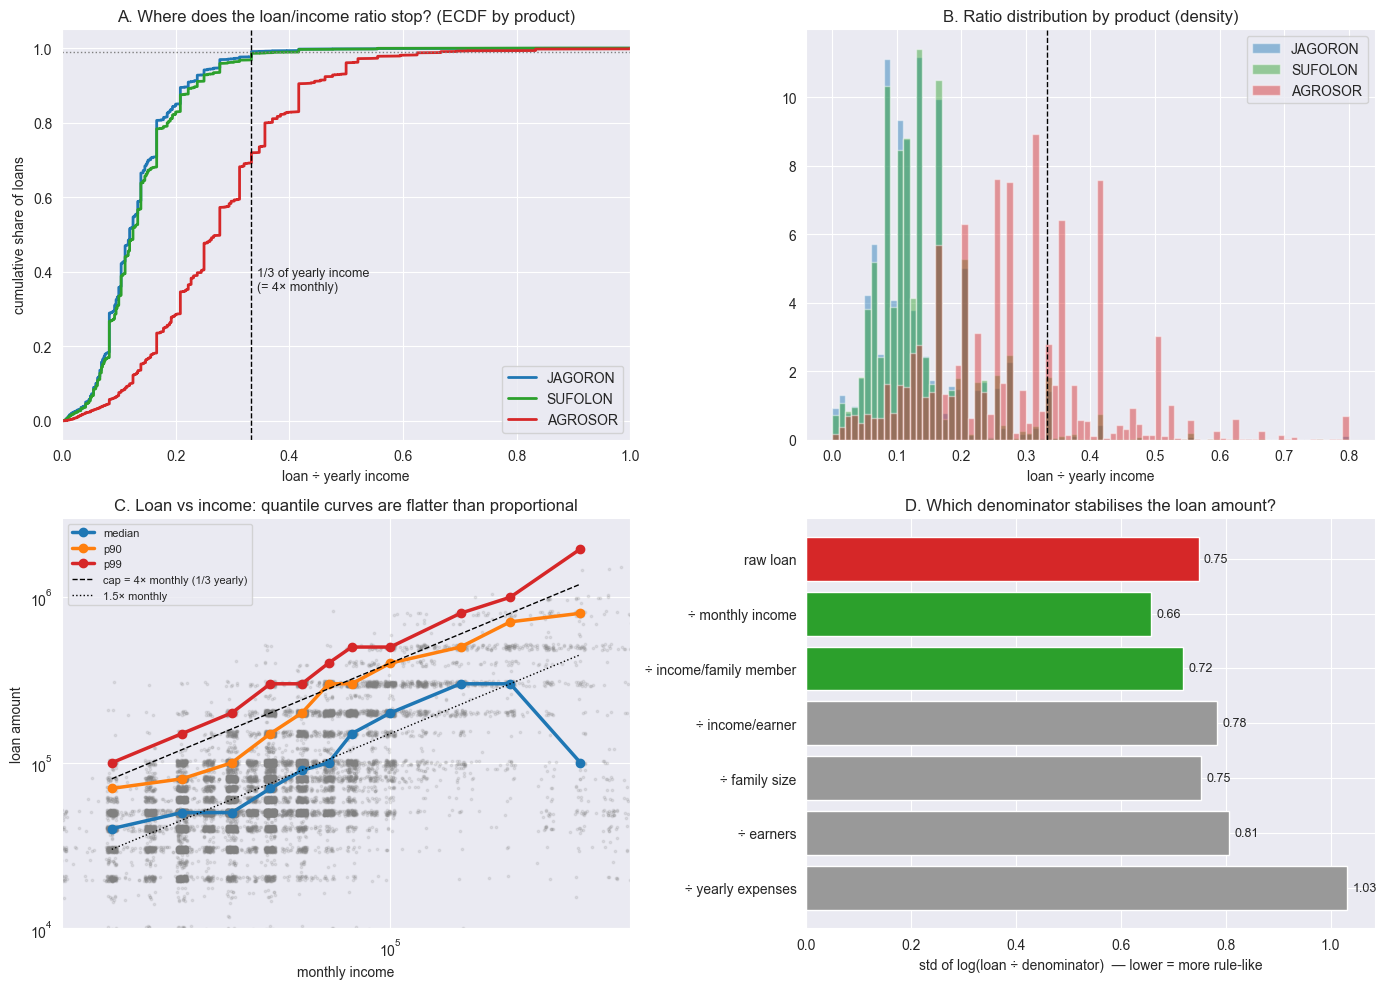

In [9]:
y = df.loan_amount

# Clip tiny/zero incomes so ratios don't explode
m = df.total_monthly_income.clip(lower=5000)
r = y / (m * 12)                 # loan / yearly income

# Product groups: AGROSOR* variants merged, JAGORON and SUFOLON kept separate
df["prod"] = np.where(
    df.loan_Component.str.startswith("AGROSOR"), "AGROSOR",
    np.where(df.loan_Component.isin(["JAGORON", "SUFOLON"]), df.loan_Component, "other"),
)
cols = {"JAGORON": "#1f77b4", "SUFOLON": "#2ca02c", "AGROSOR": "#d62728"}

# Share of loans under a candidate cap, per product (printed for reference)
for p, c in [("JAGORON", 1/3), ("SUFOLON", 1/3), ("AGROSOR", 1/3), ("AGROSOR", .5), ("AGROSOR", 2/3)]:
    s = r[df["prod"] == p]
    print(f"{p}: share of loans <= {c:.3f} of yearly income = {(s <= c + 1e-9).mean():.3%} (n={len(s)})")

fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# ---- A. ECDF by product ----------------------------------------------------
a = ax[0, 0]
for p, c in cols.items():
    s = np.sort(r[df["prod"] == p])
    a.plot(s, np.arange(1, len(s) + 1) / len(s), color=c, label=p, lw=2)
a.axvline(1/3, color="k", ls="--", lw=1)
a.text(1/3 + .01, .35, "1/3 of yearly income\n(= 4× monthly)", fontsize=9)
a.axhline(.99, color="gray", ls=":", lw=1)
a.set_xlim(0, 1)
a.set_xlabel("loan ÷ yearly income")
a.set_ylabel("cumulative share of loans")
a.set_title("A. Where does the loan/income ratio stop? (ECDF by product)")
a.legend(loc="lower right")

# ---- B. Histogram by product ----------------------------------------------
a = ax[0, 1]
bins = np.linspace(0, .8, 81)
for p, c in cols.items():
    a.hist(r[df["prod"] == p].clip(upper=.8), bins=bins, density=True, alpha=.45, color=c, label=p)
a.axvline(1/3, color="k", ls="--", lw=1)
a.set_title("B. Ratio distribution by product (density)")
a.set_xlabel("loan ÷ yearly income")
a.legend()

# ---- C. Loan vs income with quantile curves -------------------------------
a = ax[1, 0]
s = df.sample(20000, random_state=0)
mm = s.total_monthly_income.clip(lower=5000)
# small jitter so the "ladder" of repeated values is visible
a.scatter(mm * (1 + np.random.RandomState(0).uniform(-.03, .03, len(s))),
          s.loan_amount * (1 + np.random.RandomState(1).uniform(-.04, .04, len(s))),
          s=3, alpha=.15, color="gray")

grid = np.array([20, 30, 40, 50, 60, 70, 80, 100, 150, 200, 300]) * 1000
dfq = pd.DataFrame({"m": m, "y": y})
dfq["b"] = pd.cut(dfq.m, [0] + list((grid[:-1] + grid[1:]) / 2) + [1e9], labels=grid)
q = dfq.groupby("b", observed=False).y.quantile([.5, .9, .99]).unstack()
for qq, c, l in [(.5, "#1f77b4", "median"), (.9, "#ff7f0e", "p90"), (.99, "#d62728", "p99")]:
    a.plot(grid, q[qq].values, color=c, lw=2.5, marker="o", label=l)
a.plot(grid, 4 * grid, "k--", lw=1, label="cap = 4× monthly (1/3 yearly)")
a.plot(grid, 1.5 * grid, "k:", lw=1, label="1.5× monthly")
a.set_xscale("log"); a.set_yscale("log")
a.set_xlim(15000, 400000); a.set_ylim(10000, 3e6)
a.set_xlabel("monthly income"); a.set_ylabel("loan amount")
a.set_title("C. Loan vs income: quantile curves are flatter than proportional")
a.legend(fontsize=8)

# ---- D. Which denominator stabilises the loan? ----------------------------
a = ax[1, 1]
fam = df.total_family_member.replace(0, np.nan)
earn = df.total_earning_member.replace(0, np.nan)
den = {
    "raw loan": 1.0,
    "÷ monthly income": m,
    "÷ income/family member": m / fam,
    "÷ income/earner": m / earn,
    "÷ family size": fam,
    "÷ earners": earn,
    "÷ yearly expenses": df.yearly_total_expenses.replace(0, np.nan),
}
v = {k: np.log(y / d).replace([np.inf, -np.inf], np.nan).std() for k, d in den.items()}
keys = list(v)[::-1]
bars = a.barh(keys, [v[k] for k in keys],
              color=["#d62728" if k == "raw loan" else ("#2ca02c" if v[k] < v["raw loan"] else "#999999") for k in keys])
a.set_xlabel("std of log(loan ÷ denominator)  — lower = more rule-like")
a.set_title("D. Which denominator stabilises the loan amount?")
for b_, k in zip(bars, keys):
    a.text(v[k] + .01, b_.get_y() + b_.get_height() / 2, f"{v[k]:.2f}", va="center", fontsize=9)

plt.tight_layout()


In [ ]:
# every loan of 300,000 or more is an AGROSOR product, and AGROSOR’s minimum is exactly 300,000, JAGORON tops out at 295k and SUFOLON at 290k
# home_owner_type is an office habit, not a borrower trait. It ranges from about 0% in some districts to 75% in Sherpur.
#The median loan-to-income ratio climbed from 1.25× (Q1 2024) to 1.67× (2026), and the median loan from 50k to 80k, while median income stayed at 50k

# Borrowers who share purpose, income and proposer (in groups of at least 5, measured in-sample, so optimistic) still have a log-loan standard deviation of 0.37.
# Only 43.5% of them get the group’s single most common amount.
# The out-of-sample model error is 0.46. So there is little room left, perhaps 0.40, and exact-amount accuracy can’t realistically exceed about 40%. The remaining variation comes from information this data doesn’t contain.
# People with the same income, same loan purpose, and same proposer do not borrow the same amount. So there is a limit to accurately estimating how much money to borrow based on this information alone.

## clean
# Cap income at the 99.9th percentile.
# Null the 47 land values above 100,000 units (the int32 sentinel).
# Normalize alternative_occupation and purpose.
# Strip leading zeros from proposer IDs (3,162 → 3,147).
# Handle 221 borrowers who were under 18 at admission.
# Note that 96% of rows are admissions from late 2024 to 2025.


# target
# It is a ladder, not a continuous variable. 97% of loans are multiples of 10k, and 15 values cover 95% of rows.
# 8.5% of loans are 300k or more, but they carry 33% of the money. Of those, 62% are exactly 300k and 20% are 500k
# 95% of big loans go to borrowers declaring more than 50k a month. Land helps too: 33% of those with more than 300 units get big loans, versus 6% with none. Loan size is a soft ceiling of about 1.5× monthly income at the median and 5.6× at the 99th percentile, with spikes at exactly 1× and 2×. There is no hard cap
#